# Regression Exam Bootcamp 🇹🇭 — Colab สำหรับติวเพื่อน
**เป้าหมาย:** CSV → EDA → Missing/Encoding → Split → Regression from scratch → Evaluation → Library Regression → Predict ข้อมูลใหม่

> ใช้ `Runtime → Run all` ได้ทันทีด้วยข้อมูลตัวอย่าง หากมี CSV ข้อสอบ ให้เปลี่ยน `USE_DEMO=False` และ `TARGET_COL` ในส่วนตั้งค่า

**กติกา:** ข้อ 1 โมเดลต้องเขียนเอง (ใช้ NumPy คำนวณ); ข้อ 2 ใช้ sklearn ได้ *หากอาจารย์อนุญาต*; preprocessing และ metrics ต้องเช็กขอบเขตที่อนุญาตอีกครั้ง

**วิธีแชร์:** Upload notebook ไป Google Drive → Open with Colab → Share (Viewer) → เพื่อนเลือก File → Save a copy in Drive


## Slide 1 — Roadmap / ก่อนเริ่มสอบ
1. `pd.read_csv` หรือ Upload CSV
2. ระบุ **Target** เป็นค่าต่อเนื่อง (ไม่ใช่ชื่อกลุ่ม)
3. ตรวจ `head`, `info`, `isna`, duplicates และชนิดข้อมูล
4. แบ่ง Train/Validation/Test **ก่อน fit preprocessing**
5. Numeric: impute median + scale; Categorical: impute most frequent + OneHot
6. Train from scratch และทดสอบ Library models
7. เลือกโมเดลด้วย Validation; รายงาน Test ครั้งสุดท้าย

**อ้างอิงอาจารย์:** `W2_4_FeatureEngineering.ipynb` เซลล์ 4, 10–17 (scaling/encoding), 33–44 (missing values); `W3-1b_Linear_PolynomialRegression.ipynb` เซลล์ 6–7 (scratch)


In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
USE_DEMO = False
CSV_PATH = 'Mock_Regression_HousePrice_Mixed.csv'
TARGET_COL = 'target'
# True: เปิดหน้าต่างอัปโหลด CSV จากเครื่อง (ใน Colab)
UPLOAD_CSV = True


## Slide 2 — Load CSV + ตรวจชนิดข้อมูล
**อ้างอิง:** `W2_4_FeatureEngineering.ipynb` เซลล์ 4, 6–8 และ 33–35 (DataFrame/สำรวจข้อมูล)

ถ้า CSV ใช้ `;` แทน `,` ให้เปลี่ยน `pd.read_csv(path, sep=';')`; ถ้า encoding มีปัญหา ลอง `encoding='utf-8-sig'` หรือ encoding ที่ไฟล์ใช้จริง


In [6]:
df = pd.read_csv(CSV_PATH)

print('shape:', df.shape)
display(df.head())
display(df.dtypes.to_frame('dtype'))
display(df.isna().sum().to_frame('missing'))
print('duplicates:', df.duplicated().sum())
assert TARGET_COL in df.columns, f'ไม่พบ target: {TARGET_COL}; คอลัมน์มี {df.columns.tolist()}'


shape: (900, 8)


,area_sqm,building_age,bedrooms,distance_to_center_km,district,property_type,furnished,target
0,NaN,28.5,4,18.58,Industrial,Condo,Yes,17.01
1,149.78,43.0,5,9.97,Central,Condo,No,187.98
2,116.12,18.3,5,22.29,Riverside,House,No,96.56
3,97.25,16.6,1,13.83,Central,Condo,Yes,104.64
4,94.21,3.9,2,4.32,Suburban,Condo,Yes,121.20


,dtype
area_sqm,float64
building_age,float64
bedrooms,int64
distance_to_center_km,float64
district,object
property_type,object
furnished,object
target,float64


,missing
area_sqm,32
building_age,18
bedrooms,0
distance_to_center_km,0
district,27
property_type,0
furnished,20
target,0


duplicates: 0


## Slide 3 — Target และ Data Leakage
**อ้างอิง:** `W3-1a_Linear-PolynomialRegression_Hours2GPA.ipynb` เซลล์ 1–3 (X → GPA); `W2_4_FeatureEngineering.ipynb` เซลล์ 55–62 (feature selection)

- Target ต้องเป็นตัวเลขต่อเนื่องสำหรับ Regression
- ลบ ID, ข้อมูลหลังเหตุการณ์, หรือคอลัมน์ที่เฉลย Target (ถ้ามี) ด้วย `DROP_COLS`
- ตัวอย่างนี้รองรับ numeric + categorical; ไม่แปลงชื่อกลุ่มเป็นเลขเรียงลำดับโดยพลการ
- ถ้า Target เป็นข้อความที่แทนตัวเลขจริง เช่น `1,200` ต้องทำความสะอาดก่อน `to_numeric`


In [7]:
DROP_COLS = []  # เช่น ['customer_id', 'price_after_sale']
df = df.dropna(subset=[TARGET_COL]).copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='raise')
X = df.drop(columns=[TARGET_COL] + DROP_COLS)
y = df[TARGET_COL].astype(float)
# ลบคอลัมน์ว่างทั้งคอลัมน์ (ป้องกัน imputer ลบ feature เงียบๆ)
X = X.dropna(axis=1, how='all')
assert len(X) >= 10 and X.shape[1] > 0
print('X:', X.shape, 'y:', y.shape)
print('Target summary:'); display(y.describe())


X: (900, 7) y: (900,)
Target summary:


count    900.000000
mean     126.513167
std       52.670415
min        9.010000
25%       87.650000
50%      122.295000
75%      161.025000
max      288.610000
Name: target, dtype: float64

## Slide 4 — Split: Train / Validation / Test
**อ้างอิง:** `W9_HW_Gradient_Descent.ipynb` เซลล์ 4, 6–7 (เตรียม dataset และ train/validation); `W5-2_Random_Forest.ipynb` เซลล์ 11–13 (split/test)

60% train, 20% validation, 20% test; **อย่า fit encoder/scaler บนข้อมูลทั้งหมดก่อน split**


In [8]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, random_state=SEED)
print('Train/Val/Test:', len(X_train), len(X_val), len(X_test))
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.columns.difference(num_cols).tolist()
print('numeric:', num_cols)
print('categorical:', cat_cols)


Train/Val/Test: 540 180 180
numeric: ['area_sqm', 'building_age', 'bedrooms', 'distance_to_center_km']
categorical: ['district', 'furnished', 'property_type']


## Slide 5 — Preprocessing: Impute + OneHot + Standardize
**อ้างอิง:** `W2_4_FeatureEngineering.ipynb` เซลล์ 10–17 (scaling/encoding), 33–44 (missing)
- Numerical → Median → StandardScaler
- Categorical → Most frequent → OneHotEncoder(handle_unknown='ignore')
- Fit เฉพาะ Train; transform Validation/Test
- OneHot ใช้กับข้อมูลหมวดหมู่ที่ไม่มีลำดับ เช่น สี จังหวัด ประเภทสินค้า


In [9]:
num_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
cat_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocess = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
], remainder='drop', sparse_threshold=0)
Xtr = np.asarray(preprocess.fit_transform(X_train), dtype=float)
Xva = np.asarray(preprocess.transform(X_val), dtype=float)
Xte = np.asarray(preprocess.transform(X_test), dtype=float)
print('Encoded shapes:', Xtr.shape, Xva.shape, Xte.shape)


Encoded shapes: (540, 13) (180, 13) (180, 13)


## Slide 6 — Linear Regression from scratch (Gradient Descent)
**อ้างอิง:** `W3-1b_Linear_PolynomialRegression.ipynb` เซลล์ 6–7; `W3-1a_Linear-PolynomialRegression_Hours2GPA.ipynb` เซลล์ 2–3

สมการ: `y_hat = X @ w + b`  
Loss: `MSE = mean((y_hat-y)**2)`  
Gradient: `dw = 2/n * X.T @ (y_hat-y)` และ `db = 2 * mean(y_hat-y)`  
Update: `w -= learning_rate * dw`; `b -= learning_rate * db`

**หมายเหตุ:** ใช้ sklearn เฉพาะ preprocessing/split; หากโจทย์ห้าม Library ทั้งหมดต้องเขียนส่วนเหล่านั้นเองด้วย


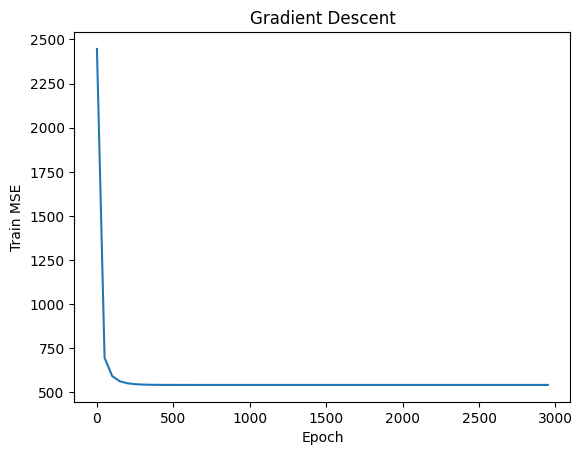

First/last train loss: 2446.5052786947977 542.8351242985362


In [10]:
class LinearRegressionScratch:
    def __init__(self, learning_rate=0.03, epochs=3000):
        self.learning_rate, self.epochs = learning_rate, epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        n, p = X.shape
        self.w = np.zeros(p)
        self.b = float(y.mean())  # ช่วยให้ converge เร็วเมื่อ y มีค่าเฉลี่ยสูง
        self.loss_history = []
        for epoch in range(self.epochs):
            err = X @ self.w + self.b - y
            dw = (2 / n) * (X.T @ err)
            db = 2 * err.mean()
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db
            if epoch % 50 == 0:
                loss = np.mean((X @ self.w + self.b - y)**2)
                self.loss_history.append(loss)
                if not np.isfinite(loss):
                    raise ValueError('Loss diverged: ลด learning_rate')
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.w + self.b

scratch = LinearRegressionScratch(learning_rate=0.03, epochs=3000).fit(Xtr, y_train)
plt.plot(np.arange(len(scratch.loss_history))*50, scratch.loss_history)
plt.xlabel('Epoch'); plt.ylabel('Train MSE'); plt.title('Gradient Descent'); plt.show()
print('First/last train loss:', scratch.loss_history[0], scratch.loss_history[-1])


## Slide 7 — Metrics / แปลผล
**อ้างอิง:** `W3-1a_Linear-PolynomialRegression_Hours2GPA.ipynb` เซลล์ 10 (R²); `W9_HW_Gradient_Descent.ipynb` เซลล์ 6–7 (training loss)

- MAE / RMSE: ยิ่งต่ำยิ่งดี; มีหน่วยเดียวกับ Target
- R²: ยิ่งสูงยิ่งดี (อาจติดลบได้)
- ดู Validation ก่อน; Test ประเมินเมื่อเลือกโมเดลเสร็จ


In [11]:
def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred)
    }

scratch_val = metrics(y_val, scratch.predict(Xva))
print('Scratch validation:', scratch_val)
display(pd.DataFrame({'actual': y_val.iloc[:10].to_numpy(),
                      'predicted': scratch.predict(Xva)[:10]}))


Scratch validation: {'MAE': np.float64(18.059882734801658), 'RMSE': np.float64(22.51855153999736), 'R2': 0.7976900935532553}


,actual,predicted
0,201.15,186.772251
1,152.42,144.446303
2,159.21,178.134061
3,101.46,121.337811
4,194.92,193.915159
5,136.24,126.494275
6,77.06,74.142934
7,174.98,190.697996
8,177.33,172.438324
9,156.46,110.603323


## Slide 8A — MLP Regression from scratch: Forward / Backpropagation
**อ้างอิงแนวคิด:** `W9_HW_Gradient_Descent.ipynb` (gradient/loss) และ `W3-1b_Linear_PolynomialRegression.ipynb` (optimization) — โค้ด MLP ด้านล่างเป็นตัวอย่างใหม่ ไม่ใช่โค้ดที่คัดลอกมาจากอาจารย์

สถาปัตยกรรม: **Input → Dense(32) → ReLU → Dense(16) → ReLU → Dense(1)**

- `Z1 = X @ W1 + b1`; `A1 = ReLU(Z1)`; `Z2 = A1 @ W2 + b2`; `A2 = ReLU(Z2)`; `pred = A2 @ W3 + b3`
- `MSE = mean((pred-y)**2)`; ย้อน gradient ด้วย Chain Rule
- Standardize **X** ด้วย preprocessing เดิม และ **y** ด้วยค่าเฉลี่ย/ส่วนเบี่ยงเบนมาตรฐานของ Train เท่านั้น
- Adam ที่เขียนเองช่วยให้ฝึกง่ายขึ้น; ใช้ Validation เพื่อตรวจ Overfit; **ไม่แตะ Test จนกว่าจะเลือกโมเดลเสร็จ**


MLP Validation: {'MAE': np.float64(15.683932089582413), 'RMSE': np.float64(19.563173955222698), 'R2': 0.8473084939649084}


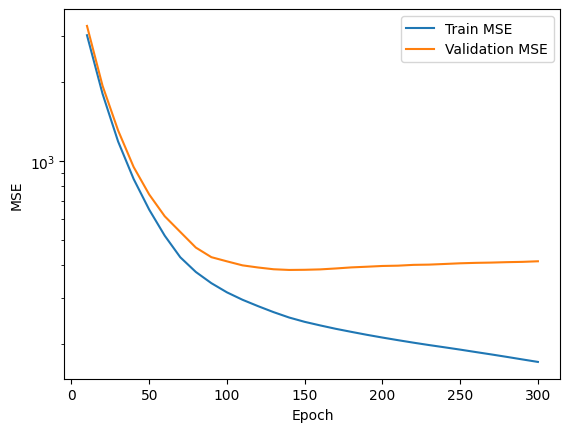

In [12]:
class MLPScratch:
    def __init__(self, hidden=(32,16), lr=0.003, epochs=1800, seed=42, l2=0.0001):
        self.hidden, self.lr, self.epochs, self.seed, self.l2 = hidden, lr, epochs, seed, l2

    def fit(self, X, y, X_val=None, y_val=None):
        X=np.asarray(X,dtype=float)
        y=np.asarray(y,dtype=float).reshape(-1,1)
        self.y_mean=float(y.mean())
        self.y_std=float(y.std()) if y.std()>1e-12 else 1.
        Y=(y-self.y_mean)/self.y_std
        rng=np.random.default_rng(self.seed)
        dims=[X.shape[1], *self.hidden, 1]
        self.W=[rng.normal(0,np.sqrt(2/dims[i]),(dims[i],dims[i+1])) for i in range(3)]
        self.B=[np.zeros((1,dims[i+1])) for i in range(3)]
        params=self.W+self.B
        m=[np.zeros_like(p) for p in params]
        v=[np.zeros_like(p) for p in params]
        self.history=[]
        best=float('inf')
        best_params=None
        patience=160
        stale=0
        for t in range(1,self.epochs+1):
            Z1=X@self.W[0]+self.B[0]; A1=np.maximum(0,Z1)
            Z2=A1@self.W[1]+self.B[1]; A2=np.maximum(0,Z2)
            P=A2@self.W[2]+self.B[2]
            D=2*(P-Y)/len(X)
            gW3=A2.T@D+self.l2*self.W[2]; gB3=D.sum(axis=0,keepdims=True)
            D2=(D@self.W[2].T)*(Z2>0)
            gW2=A1.T@D2+self.l2*self.W[1]; gB2=D2.sum(axis=0,keepdims=True)
            D1=(D2@self.W[1].T)*(Z1>0)
            gW1=X.T@D1+self.l2*self.W[0]; gB1=D1.sum(axis=0,keepdims=True)
            grads=[gW1,gW2,gW3,gB1,gB2,gB3]
            for j,(p,g) in enumerate(zip(params,grads)):
                m[j]=.9*m[j]+.1*g
                v[j]=.999*v[j]+.001*g*g
                p-=self.lr*(m[j]/(1-.9**t))/(np.sqrt(v[j]/(1-.999**t))+1e-8)
            if t%10==0:
                train_mse=float(np.mean((self.predict(X)-y.ravel())**2))
                val_mse=float(np.mean((self.predict(X_val)-np.asarray(y_val))**2)) if X_val is not None else train_mse
                self.history.append((t,train_mse,val_mse))
                if val_mse<best-1e-6:
                    best=val_mse; stale=0
                    best_params=[p.copy() for p in params]
                else:
                    stale+=10
                if stale>=patience: break
        if best_params is not None:
            for p,q in zip(params,best_params): p[:]=q
        return self

    def predict(self, X):
        X=np.asarray(X,dtype=float)
        a=np.maximum(0,X@self.W[0]+self.B[0])
        a=np.maximum(0,a@self.W[1]+self.B[1])
        return (a@self.W[2]+self.B[2]).ravel()*self.y_std+self.y_mean

mlp=MLPScratch(lr=0.003,epochs=1800).fit(Xtr,y_train,Xva,y_val)
print('MLP Validation:',metrics(y_val,mlp.predict(Xva)))
history=np.array(mlp.history)
plt.plot(history[:,0],history[:,1],label='Train MSE')
plt.plot(history[:,0],history[:,2],label='Validation MSE')
plt.yscale('log'); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend(); plt.show()


## Slide 8B — Compare scratch Linear vs scratch MLP
**ทดลองเปลี่ยน** `hidden=(16,8)` / `(64,32)`, `lr=0.001` / `0.003`, `l2=0.0001` / `0.001` โดยเลือกจาก Validation เท่านั้น

Dataset ตัวอย่างมีผลของระยะทางแบบ sine, พื้นที่แบบกำลังสอง และ interaction ระหว่างเขตกับพื้นที่ จึงออกแบบมาเพื่อทดสอบความสามารถ Non-linear; ไม่รับประกันว่า MLP จะชนะทุกครั้ง


In [13]:
comparison=pd.DataFrame([
    {'model':'Linear Scratch',**metrics(y_val,scratch.predict(Xva))},
    {'model':'MLP Scratch',**metrics(y_val,mlp.predict(Xva))}
]).sort_values('RMSE')
display(comparison)


,model,MAE,RMSE,R2
1,MLP Scratch,15.683932,19.563174,0.847308
0,Linear Scratch,18.059883,22.518552,0.797690


## Slide 8 — ข้อ 2: Library Regression / ทดลองหลายโมเดล
**อ้างอิง:** `W3-1b_Linear_PolynomialRegression.ipynb` เซลล์ 12, 23–27 (sklearn linear/polynomial); `W5-2_Random_Forest.ipynb` เซลล์ 2, 11–13 (หลักการ Random Forest — ในต้นฉบับเป็น *Classifier* ต้องใช้ Regressor แทน)

ใช้ preprocessing เดิมที่ fit จาก Train แล้ว และเลือกโมเดลจาก **Validation RMSE** เท่านั้น


In [14]:
models = {
    'Scratch GD': scratch,
    'MLP Scratch': mlp,
    'LinearRegression': LinearRegression(),
    'Ridge(alpha=10)': Ridge(alpha=10),
    'RandomForest': RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                          random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=SEED)
}
rows = []
for name, model in models.items():
    if name not in ('Scratch GD', 'MLP Scratch'):
        model.fit(Xtr, y_train)
    scores = metrics(y_val, model.predict(Xva))
    rows.append({'model': name, **scores})
results = pd.DataFrame(rows).sort_values('RMSE')
display(results)
best_name = results.iloc[0]['model']
best_model = models[best_name]
print('Selected by validation:', best_name)


,model,MAE,RMSE,R2
5,HistGradientBoosting,12.273789,15.962626,0.898341
4,RandomForest,15.028654,18.851714,0.858213
1,MLP Scratch,15.683932,19.563174,0.847308
0,Scratch GD,18.059883,22.518552,0.797690
2,LinearRegression,18.059883,22.518552,0.797690
3,Ridge(alpha=10),18.197888,22.558416,0.796973


Selected by validation: HistGradientBoosting


## Slide 9 — Final Test + Predict ข้อมูลใหม่
**อ้างอิง:** `W3-1b_Linear_PolynomialRegression.ipynb` เซลล์ 10–15 (predict); `W5-2_Random_Forest.ipynb` เซลล์ 12–13 (test evaluation)

นี่คือการประเมิน Test ครั้งสุดท้ายหลังเลือกโมเดลแล้ว เพื่อไม่ให้เกิดการเลือกโมเดลตาม Test


FINAL TEST: HistGradientBoosting {'MAE': np.float64(13.724624551938117), 'RMSE': np.float64(17.855462643311213), 'R2': 0.9075219325382917}


,actual,predicted
0,52.48,64.115266
1,194.98,182.505739
2,133.86,127.290125
3,96.47,100.931379
4,66.53,78.719347
5,186.65,162.399485
6,180.06,179.763435
7,246.49,163.697952
8,202.76,207.244319
9,49.62,60.430757


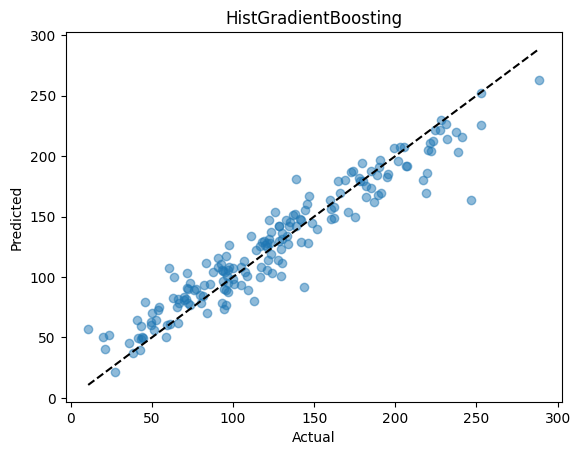

New predictions: [ 64.11526616 182.50573857]


In [15]:
test_pred = best_model.predict(Xte)
print('FINAL TEST:', best_name, metrics(y_test, test_pred))
display(pd.DataFrame({'actual': y_test.to_numpy()[:10], 'predicted': test_pred[:10]}))
plt.scatter(y_test, test_pred, alpha=.5)
lo = min(y_test.min(), test_pred.min())
hi = max(y_test.max(), test_pred.max())
plt.plot([lo, hi], [lo, hi], 'k--')
plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title(best_name); plt.show()

# ใช้ข้อมูล 2 แถวแรกเป็นตัวอย่าง input ใหม่ (ไม่มี target)
new_data = X_test.iloc[:2].copy()
new_encoded = preprocess.transform(new_data)
print('New predictions:', best_model.predict(new_encoded))


## Slide 10 — ถ้าโจทย์บอก “นำ Classification มาต่อ Regression”
**อ้างอิง:** `W4-1_Logistic Regression.ipynb` เซลล์ 4–12 (Classifier/probability); `W5-2_Random_Forest.ipynb` เซลล์ 31–33 (แนวคิด stacking classifiers)

**สองความหมายที่เป็นไปได้:**
1. ใช้ Dataset เดิม แต่เลือก Target แบบตัวเลขต่อเนื่อง → ทำ Regression ได้เลย
2. นำ Probability จาก Classifier มาเป็น Feature ของ Regressor → ต้องทำ out-of-fold prediction เพื่อเลี่ยง leakage

ห้ามนำชื่อกลุ่ม (`low/medium/high`) มาอ้างว่าเป็นค่าต่อเนื่องจริงโดยไม่มีนิยามเป้าหมายและข้อมูลอ้างอิง

**ตัวอย่างแนวคิด (ไม่รัน):**
```python
# class_probability_oof = cross_val_predict(
#     classifier, X_train_encoded, class_y_train,
#     cv=5, method='predict_proba'
# )
# X_train_plus = np.column_stack([X_train_encoded, class_probability_oof])
# regressor.fit(X_train_plus, regression_y_train)
```
สำหรับชุด Test ต้องใช้ Classifier ที่ฝึกจาก Train เท่านั้นเพื่อสร้าง probability; ห้าม fit จาก Test


## Slide 11 — Cheat Sheet: Error ที่เจอบ่อย
| Error / อาการ | เช็กอะไร |
|---|---|
| `KeyError: target` | `print(df.columns.tolist())` แล้วแก้ `TARGET_COL` |
| `could not convert string to float` | มี categorical ที่ยังไม่ OneHot |
| `Input contains NaN` | Imputer / Target missing |
| `Found unknown categories` | OneHot ต้อง `handle_unknown='ignore'` |
| Loss เป็น `nan` หรือพุ่ง | ลด learning rate, ตรวจ inf/target scale |
| Train ดี Test แย่ | Overfit / leakage / data shift |
| R² ติดลบ | โมเดลแย่กว่า baseline เฉลี่ยของ Test |
| CSV โหลดไม่ได้ | path, separator, encoding |

**ก่อนสอบ:** ลอง CSV ใหม่ 2–3 แบบ (numeric-only, mixed numeric/categorical, missing values) และลองเปลี่ยน Target เพื่อให้แน่ใจว่า template ใช้ได้จริง
